# Qlang: compile Python expressions into quantum circuits

Write a condition in plain Python. Qlang builds an expression tree, optimizes it, compiles it into a quantum circuit, and searches for inputs that satisfy it.

**In this demo**

1. The pitch
2. ASTNode
3. Optimizer
4. Classical check
5. Gates
6. Quantum circuits
7. Oracle truth table
8. Grover search
9. Amplification
10. BBHT
11. QAOA search

## Setup

Run this cell first. It installs Qlang if it's missing, then loads everything the demo needs. Longer helper code, like the chart, is in `demo_helpers.py` next to this notebook.

In [1]:
import importlib.util

if importlib.util.find_spec("qlang") is None:
    %pip install "qlang @ git+https://github.com/asherhe/qlang" "qiskit[visualization]>=2.0" "qiskit-aer>=0.17" "qiskit-ibm-runtime>=0.40" matplotlib pylatexenc

from qiskit import QuantumCircuit

from qlang import compile_oracle, evaluate, optimize_expr, print_ast, search
from qlang.minimize import qaoa

from demo_helpers import PARAMS, find_solutions, fresh_variables, plot_amplification, print_truth_table, traced_search

## 1. The pitch

Plain Python in, a quantum search out. `x` is a 3-bit number (0 to 7) and `y` is a 2-bit number (0 to 3).

In [2]:
x, y = fresh_variables()

search(PARAMS, x + y == 5)

{'x': 5, 'y': 0}

## 2. ASTNode

Python operators don't calculate anything here. They build an expression tree made of `ASTNode`s: `Bit` for true/false values and `UInt` for integers.

In [3]:
x, y = fresh_variables()

print_ast(x + y == 5)

└─<Bit op==>
  ├─<UInt op+ (4-bit)>
  │ ├─<UInt x (3-bit)>
  │ └─<UInt y (2-bit)>
  └─<UInt 5 (3-bit)>


## 3. Optimizer

Before compiling, Qlang rewrites the tree into operations that are cheap to build. Multiplying by 2 just moves bits one place left, so it needs no multiplier circuit.

In [4]:
x, y = fresh_variables()
pred = 2 * x == 6

print("Before:")
print_ast(pred)

print("\nAfter:")
print_ast(optimize_expr(pred))

Before:
└─<Bit op==>
  ├─<UInt op* (5-bit)>
  │ ├─<UInt x (3-bit)>
  │ └─<UInt 2 (2-bit)>
  └─<UInt 6 (3-bit)>

After:
└─<Bit op==>
  ├─<UInt 0 s0 s0 s0 0 (5-bit)>
  │ ├─<Bit 0>
  │ ├─<Bit <UInt x (3-bit)>[0]>
  │ │ └─<UInt x (3-bit)>
  │ ├─<Bit <UInt x (3-bit)>[1]>
  │ │ └─<UInt x (3-bit)>
  │ ├─<Bit <UInt x (3-bit)>[2]>
  │ │ └─<UInt x (3-bit)>
  │ └─<Bit 0>
  └─<UInt 6 (3-bit)>


## 4. Classical check

The same tree can also run on a normal computer. Trying every input gives us the correct answers to compare against.

In [5]:
x, y = fresh_variables()

find_solutions(x + y == 5)

[{'x': 2, 'y': 3}, {'x': 3, 'y': 2}, {'x': 4, 'y': 1}, {'x': 5, 'y': 0}]

## 5. Gates

Quantum circuits are built from gates. These five are the main ones Qlang uses:

| Gate | What it does |
|---|---|
| **H** | Puts a qubit into a superposition of 0 and 1 |
| **X** | Flips a qubit, like NOT |
| **Z** | Flips the sign of the 1 state, which is how the oracle marks solutions |
| **CX** | Flips the target if the control is 1, like XOR |
| **CCX** | Flips the target if both controls are 1, like AND |

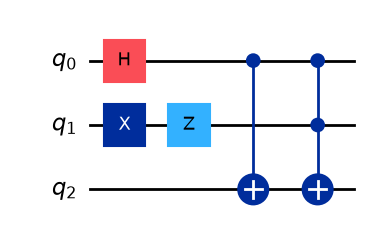

In [6]:
qc = QuantumCircuit(3)
qc.h(0)
qc.x(1)
qc.z(1)
qc.cx(0, 2)
qc.ccx(0, 1, 2)

qc.draw("mpl")

## 6. Quantum circuits

`compile_oracle` turns the tree into a circuit that marks every solution by flipping its sign. This is the whole circuit for `x == 5`: the `Z` in the middle does the marking, and the second half undoes the scratch work.

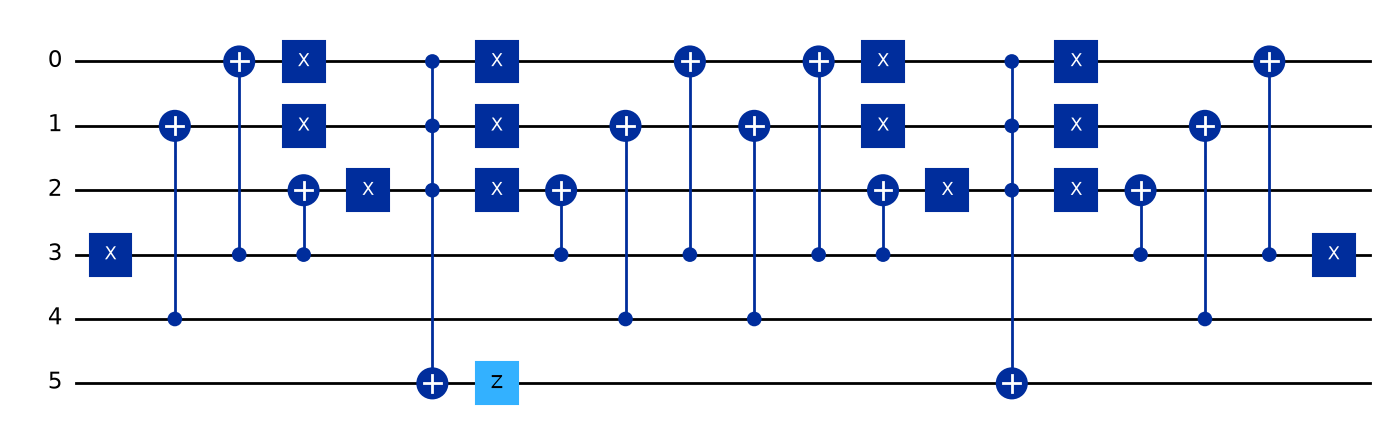

In [7]:
x, y = fresh_variables()

compile_oracle(x == 5).circuit.draw("mpl", fold=-1)

Bigger expressions need more qubits and gates.

In [8]:
x, y = fresh_variables()

for label, pred in [("x == 5", x == 5), ("x + y == 5", x + y == 5), ("3 * x + y == 5", 3 * x + y == 5)]:
    circuit = compile_oracle(pred).circuit
    print(f"{label:16} {circuit.num_qubits:3} qubits {circuit.size():4} gates")

x == 5             6 qubits   29 gates
x + y == 5        13 qubits   75 gates
3 * x + y == 5    23 qubits  181 gates


## 7. Oracle truth table

Does the circuit mark the right inputs? We run all 32 inputs through it and compare with the classical answer. A sign of `-1` means marked.

In [9]:
x, y = fresh_variables()

print_truth_table(x + y == 5)

 x  y  classical  oracle sign
 2  3  True       -1
 3  2  True       -1
 4  1  True       -1


 5  0  True       -1

32 of 32 inputs match (only solutions are listed)


## 8. Grover search

`search` runs the circuit and returns one solution. Measurement is random, so the answer can change between runs, but each one is valid.

In [10]:
x, y = fresh_variables()
pred = x + y == 5

for _ in range(5):
    result = search(PARAMS, pred)
    print(result, "valid:", bool(evaluate(pred, result)))

{'x': 5, 'y': 0} valid: True
{'x': 4, 'y': 1} valid: True


{'x': 2, 'y': 3} valid: True
{'x': 3, 'y': 2} valid: True


{'x': 3, 'y': 2} valid: True


## 9. Amplification

Grover makes solutions more likely with each iteration. `k` is the number of iterations. At `k = 0` every input is equally likely, then the solutions rise above the rest.

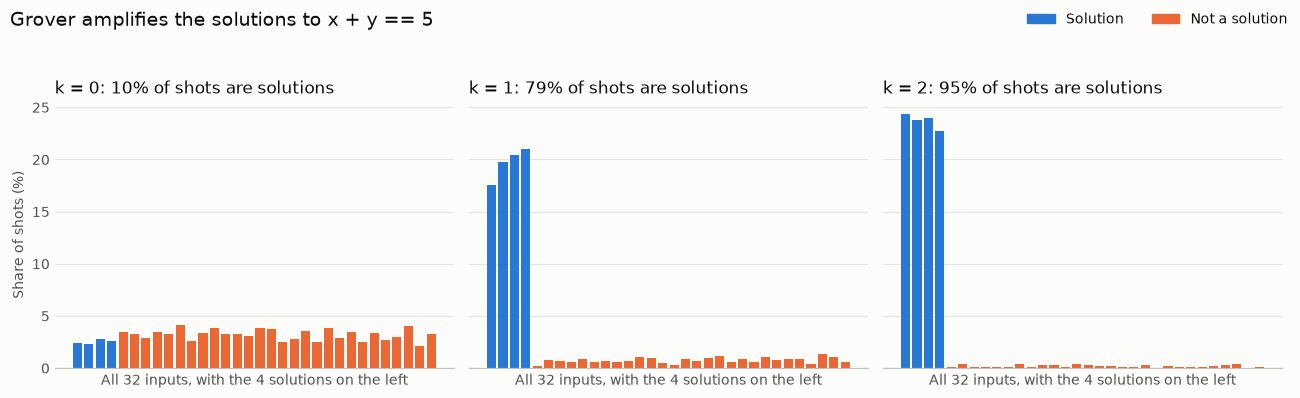

In [11]:
x, y = fresh_variables()

plot_amplification(x + y == 5, "Grover amplifies the solutions to x + y == 5")

## 10. BBHT

The best `k` depends on how many solutions exist, which we don't know in advance. BBHT picks a random `k` under a limit that grows each round, and stops at the first solution.

With one solution, it finds the answer quickly.

In [12]:
x, y = fresh_variables()

traced_search(x + y == 10)

round  1  limit 1.00  k = 1  total iterations  1  found: {'x': 7, 'y': 3}


{'x': 7, 'y': 3}

With no solution, the limit keeps growing until the budget runs out. The largest possible sum is 7 + 3 = 10, so `x + y == 11` can't be satisfied.

In [13]:
x, y = fresh_variables()

traced_search(x + y == 11)

round  1  limit 1.00  k = 1  total iterations  1  found: None
round  2  limit 1.20  k = 1  total iterations  2  found: None


round  3  limit 1.44  k = 2  total iterations  4  found: None


round  4  limit 1.73  k = 2  total iterations  6  found: None


round  5  limit 2.07  k = 1  total iterations  7  found: None


round  6  limit 2.49  k = 3  total iterations 10  found: None
round  7  limit 2.99  k = 1  total iterations 11  found: None


round  8  limit 3.58  k = 1  total iterations 12  found: None


... (7 outputs left out)

round 16  limit 5.66  k = 3  total iterations 40  found: None


round 17  limit 5.66  k = 1  total iterations 41  found: None
round 18  limit 5.66  k = 3  total iterations 44  found: None


round 19  limit 5.66  k = 3  total iterations 47  found: None


round 20  limit 5.66  k = 6  total iterations 53  found: None
budget of 51 iterations used up: most likely no solution


## 11. QAOA search (need more stuff)

The same expressions work with a second algorithm. QAOA handles optimization: among the inputs that satisfy a constraint, it looks for one with a low objective value.

Here the constraint is `x + y == 3`, and the objective is to make `x` as small as possible.

In [14]:
x, y = fresh_variables()

qaoa([x, y], x + y == 3, objective=x, penalty=4.0, iterations=8)

{'x': 0, 'y': 3}